In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df_exped = pd.read_csv("exped_tidy.csv", encoding="cp1252")
df_peaks = pd.read_csv("peaks_tidy.csv", encoding="cp1252")

df_exped.head()


,EXPID,PEAKID,YEAR,SEASON,SEASON_FACTOR,HOST,HOST_FACTOR,ROUTE1,ROUTE2,ROUTE3,...,ACCIDENTS,ACHIEVMENT,AGENCY,COMRTE,STDRTE,PRIMRTE,PRIMMEM,PRIMREF,PRIMID,CHKSUM
0,EVER20101,EVER,2020,1,Spring,2,China,N Col-NE Ridge,NaN,NaN,...,NaN,NaN,Holy Mountain Adventure,True,True,False,False,False,NaN,2465291
1,EVER20102,EVER,2020,1,Spring,2,China,N Col-NE Ridge,NaN,NaN,...,NaN,NaN,NaN,True,True,False,False,False,NaN,2465292
2,EVER20103,EVER,2020,1,Spring,2,China,N Col-NE Ridge,NaN,NaN,...,NaN,NaN,Holy Mountain Adventure,True,True,False,False,False,NaN,2465293
3,AMAD20301,AMAD,2020,3,Autumn,1,Nepal,SW Ridge,NaN,NaN,...,NaN,NaN,Seven Summit Treks,True,False,False,False,False,NaN,2463299
4,AMAD20302,AMAD,2020,3,Autumn,1,Nepal,SW Ridge,NaN,NaN,...,NaN,NaN,Himalayan Guides,True,False,False,False,False,NaN,2463299


In [ ]:
df_peaks.head()

,PEAKID,PKNAME,PKNAME2,LOCATION,HEIGHTM,HEIGHTF,HIMAL,HIMAL_FACTOR,REGION,REGION_FACTOR,...,PEAKMEMO,PYEAR,PSEASON,PEXPID,PSMTDATE,PCOUNTRY,PSUMMITERS,PSMTNOTE,REFERMEMO,PHOTOMEMO
0,AMAD,Ama Dablam,Amai Dablang,Khumbu Himal,6814,22356,12,Khumbu,2,Khumbu-Rolwaling-Makalu,...,8.0,1961.0,1,AMAD61101,Mar 13,"New Zealand, USA, UK","Mike Gill, Wally Romanes, Barry Bishop, Michae...",NaN,NaN,13.0
1,AMPG,Amphu Gyabjen,Amphu Gyabien,Khumbu Himal (N of Ama Dablam),5630,18471,12,Khumbu,2,Khumbu-Rolwaling-Makalu,...,20.0,1953.0,1,AMPG53101,Apr 11,UK,"John Hunt, Tom Bourdillon",NaN,NaN,NaN
2,ANN1,Annapurna I,NaN,Annapurna Himal,8091,26545,1,Annapurna,5,Annapurna-Damodar-Peri,...,23.0,1950.0,1,ANN150101,Jun 03,France,"Maurice Herzog, Louis Lachenal",NaN,25.0,26.0
3,ANN2,Annapurna II,NaN,Annapurna Himal,7937,26040,1,Annapurna,5,Annapurna-Damodar-Peri,...,31.0,1960.0,1,ANN260101,May 17,"UK, Nepal","Richard Grant, Chris Bonington, Ang Nyima Sherpa",NaN,33.0,34.0
4,ANN3,Annapurna III,NaN,Annapurna Himal,7555,24787,1,Annapurna,5,Annapurna-Damodar-Peri,...,35.0,1961.0,1,ANN361101,May 06,India,"Mohan S. Kohli, Sonam Gyatso, Sonam Girmi",NaN,NaN,37.0


In [ ]:
#What is the distribution of climbing status (PSTATUS) across different mountain ranges?

df_pstastus = df_peaks[["LOCATION","PSTATUS"]]
df_pstastus['LOCATION'] = df_pstastus['LOCATION'].str.replace(r'\s*\(.*?\)',"",regex=True)

grid_table = pd.crosstab(df_pstastus['LOCATION'],df_pstastus['PSTATUS'])
print(grid_table)


PSTATUS                                1   2
LOCATION                                    
Annapurna Himal                        2  19
Annapurna-Nilgiri Himal                0   6
Api Himal                              5   6
Byas Risi Himal                        2   0
Chandi Himal                           0   3
Changla Himal                          1   3
Damodar Himal                          1  25
Dhaulagiri Himal                       5  20
Ganesh Himal                           4   7
Gorakh Himal                           2   0
Gorakh Khang                           1   0
Guras Himal                            3   0
Jagdula Lekh                           2   4
Janak Himal                            3   6
Jongsang Himal                         2  10
Jugal Himal                            4  19
Kagmara Lekh                           1   2
Kangchenjunga Himal                    9  14
Kanjiroba Himal                        4  12
Kanti Himal                           10   6
Khumbu Him

/tmp/ipykernel_5214/2896445099.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_pstastus['LOCATION'] = df_pstastus['LOCATION'].str.replace(r'\s*\(.*?\)',"",regex=True)


In [ ]:
#didn't realsize mountain region is HIMAL, so continue...
#PSTATUS 1= Unclimed, 2= climbed

#df_peaks["HIMAL_FACTOR"].value_counts()

grid_table_region = pd.crosstab(df_peaks["HIMAL_FACTOR"],df_peaks['PSTATUS_FACTOR'])
print(grid_table_region)


PSTATUS_FACTOR             Climbed  Unclimbed
HIMAL_FACTOR                                 
Annapurna                       26          2
Api/Byas Risi/Guras              7         11
Damodar                         26          1
Dhaulagiri                      20          5
Ganesh/Shringi                  11          9
Janak/Ohmi Kangri               16         12
Jongsang                        10          2
Jugal                           18          4
Kangchenjunga/Simhalila         21          9
Kanjiroba                       19          7
Kanti/Palchung                   7         14
Khumbu                          67         11
Langtang                        12          2
Makalu                           6          3
Manaslu/Mansiri                 17          4
Mukut/Mustang                   13          2
Nalakankar/Chandi/Changla       12          4
Peri                            15          5
Rolwaling                       42          2
Saipal                           3

In [ ]:
grid_table_region["success_rate"] = grid_table_region["Climbed"]/(grid_table_region["Climbed"]+grid_table_region["Unclimbed"] )*100

print(grid_table_region)

PSTATUS_FACTOR             Climbed  Unclimbed  success_rate
HIMAL_FACTOR                                               
Annapurna                       26          2     92.857143
Api/Byas Risi/Guras              7         11     38.888889
Damodar                         26          1     96.296296
Dhaulagiri                      20          5     80.000000
Ganesh/Shringi                  11          9     55.000000
Janak/Ohmi Kangri               16         12     57.142857
Jongsang                        10          2     83.333333
Jugal                           18          4     81.818182
Kangchenjunga/Simhalila         21          9     70.000000
Kanjiroba                       19          7     73.076923
Kanti/Palchung                   7         14     33.333333
Khumbu                          67         11     85.897436
Langtang                        12          2     85.714286
Makalu                           6          3     66.666667
Manaslu/Mansiri                 17      

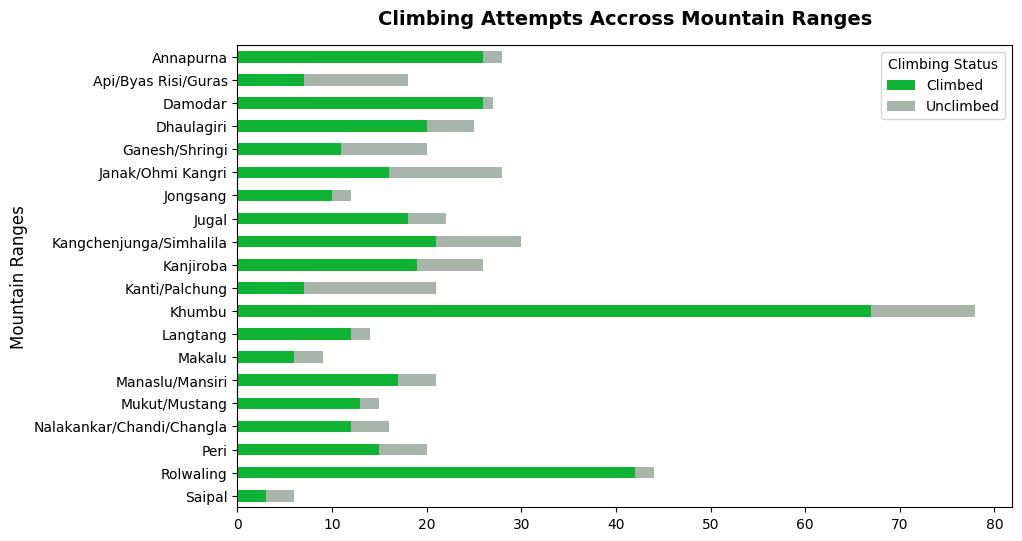

In [ ]:
grid_table_region = grid_table_region.sort_index(ascending=False)


custom_colors = ['#10b333','#a7b5aa']

grid_table_region.drop(columns = ["success_rate"]).plot(kind='barh', stacked=True, color=custom_colors, figsize=(10, 6))

plt.title("Climbing Attempts Accross Mountain Ranges", fontsize=14, fontweight='bold', pad=15)
plt.ylabel("Mountain Ranges", fontsize=12)
plt.legend(title="Climbing Status")

<Axes: ylabel='HIMAL_FACTOR'>

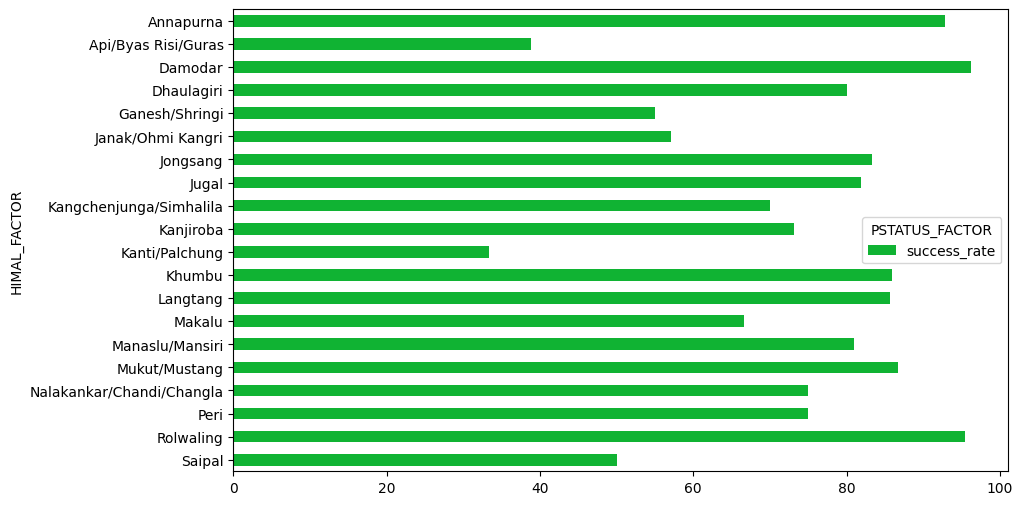

In [ ]:
grid_table_region.drop(columns = ["Climbed","Unclimbed"]).plot(kind='barh', stacked=True, color=custom_colors, figsize=(10, 6))


Text(0.5, 1.0, 'Average Height of Mountain Ranges(m) in Alphabetical Order')

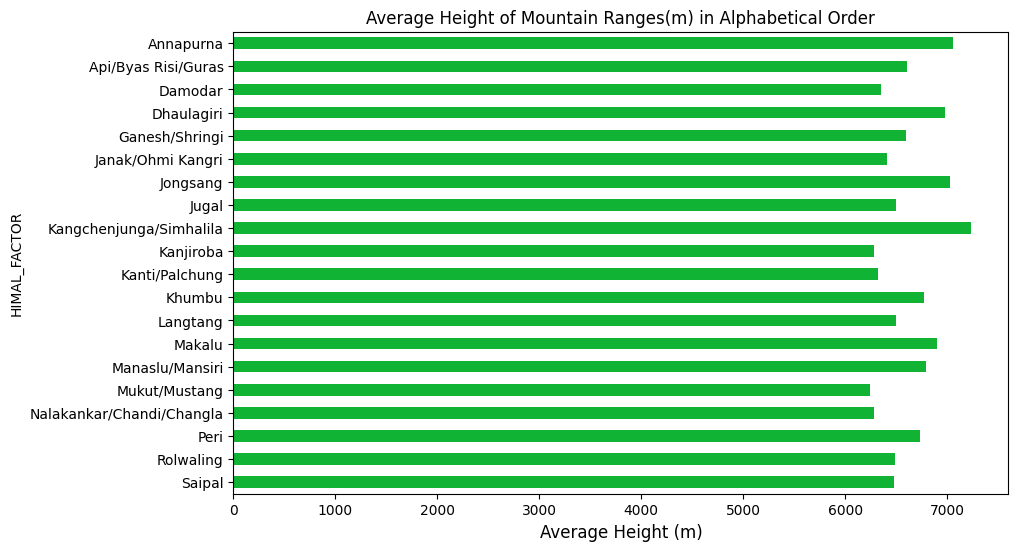

In [ ]:
#Which mountain range (HIMAL FACTOR) has the highest average peak height (HEIGHTM)?

heights_df = df_peaks[["HIMAL_FACTOR","HEIGHTM"]].groupby("HIMAL_FACTOR")["HEIGHTM"].mean()
heights_df  = heights_df.sort_index(ascending=False)
custom_colors = ['#10b333']

heights_df.plot(kind='barh', stacked=True, color=custom_colors, figsize=(10, 6))
plt.xlabel("Average Height (m)", fontsize=12)

plt.title("Average Height of Mountain Ranges(m) in Alphabetical Order")

In [ ]:
heights_df  = heights_df.round(0).astype(int).sort_values(ascending=False)

heighest_df = heights_df.head().reset_index()
heighest_df.columns =['Mountain Peak', 'Height (Meters)']

display(heighest_df)
heighest_df.to_markdown(index=False)

,Mountain Peak,Height (Meters)
0,Kangchenjunga/Simhalila,7238
1,Annapurna,7058
2,Jongsang,7032
3,Dhaulagiri,6981
4,Makalu,6901


'| Mountain Peak           |   Height (Meters) |\n|:------------------------|------------------:|\n| Kangchenjunga/Simhalila |              7238 |\n| Annapurna               |              7058 |\n| Jongsang                |              7032 |\n| Dhaulagiri              |              6981 |\n| Makalu                  |              6901 |'

In [ ]:


height_success_df = pd.merge(heights_df,grid_table_region.drop(columns = ["Climbed","Unclimbed"]) , on='HIMAL_FACTOR')

height_success_df.head()

,HEIGHTM,success_rate
HIMAL_FACTOR,,
Kangchenjunga/Simhalila,7238,70.000000
Annapurna,7058,92.857143
Jongsang,7032,83.333333
Dhaulagiri,6981,80.000000
Makalu,6901,66.666667


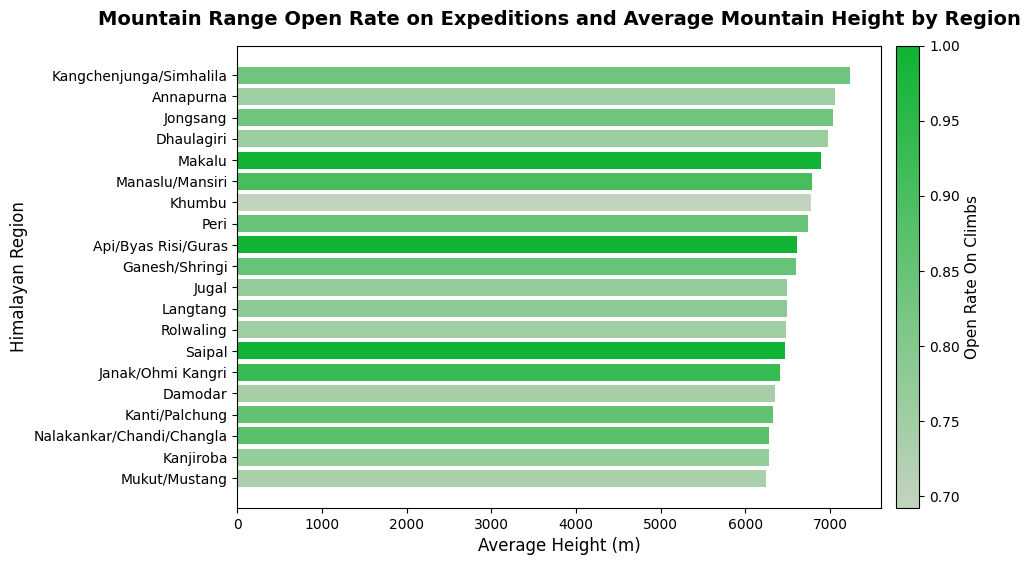

In [ ]:
#What is the distribution of peak heights (HEIGHTM) for peaks that are open (OPEN) versus those that are not?
#using height graph from before
import matplotlib.colors as mcolors

open_df = pd.crosstab(df_peaks['HIMAL_FACTOR'],df_peaks['OPEN'])
open_df["open_rate"] = open_df[True]/(open_df[True]+open_df[False])
open_df=open_df.reset_index()
heights_open_df = pd.merge(heights_df,open_df[["open_rate","HIMAL_FACTOR"]], on='HIMAL_FACTOR')

heights_open_df = heights_open_df.sort_values(by="HEIGHTM",ascending=True)
colors = ['#c2d4be','#10b333']

green_gray_cmap = mcolors.LinearSegmentedColormap.from_list("GreenGray", colors)
min_rate = heights_open_df['open_rate'].min()
max_rate = heights_open_df['open_rate'].max()

norm = mcolors.Normalize(vmin=min_rate, vmax=max_rate)

dynamic_colors = [green_gray_cmap(norm(rate)) for rate in heights_open_df['open_rate']]
#custom_colors = np.where(heights_open_df["OPEN"], '#10b333','#a7b5aa')

#heights_open_df.head()

#heights_open_df.drop(columns=["open_rate"]).plot(kind='barh',x ="HIMAL_FACTOR",y="HEIGHTM", stacked = False, color=dynamic_colors,legend=False,figsize=(10, 6))
plt.figure(figsize=(10, 6))
plt.barh(
    heights_open_df['HIMAL_FACTOR'],
    heights_open_df['HEIGHTM'],
    color=dynamic_colors,

)
plt.title("Mountain Range Open Rate on Expeditions and Average Mountain Height by Region", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Average Height (m)", fontsize=12)
plt.ylabel("Himalayan Region", fontsize=12)

sm = plt.cm.ScalarMappable(cmap=green_gray_cmap, norm=norm)
cbar = plt.colorbar(sm, ax=plt.gca(), pad=0.02)
cbar.set_label('Open Rate On Climbs', fontsize=11)
plt.show()
#plt.xlabel("Average Height (m)", fontsize=12)


#IM GIVING UP, TOO UGLY

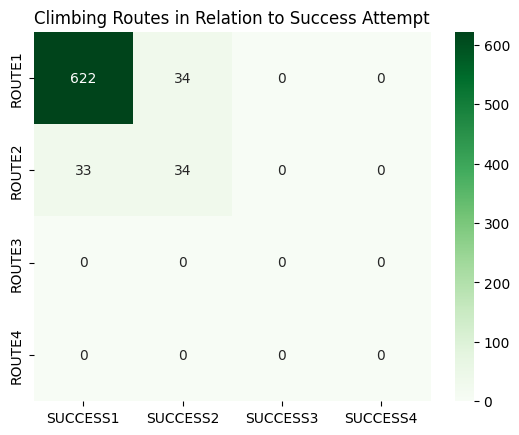

In [ ]:
#Which climbing routes (ROUTE1, ROUTE2, ROUTE3, ROUTE4) have the highest success rates (SUCCESS1, SUCCESS2, SUCCESS3, SUCCESS4) across all expeditions?

#heat map


import seaborn as sns

df_route_success = df_exped[["ROUTE1","ROUTE2","ROUTE3","ROUTE4","SUCCESS1","SUCCESS2","SUCCESS3","SUCCESS4"]]
heat_map = np.zeros((4, 4), dtype=int)
for index, row in df_route_success.iterrows():
  a = None
  b = None
  for i in range(3):

    for j in range(3):
      if pd.notna(row.iloc[i]):
        a = i
        if(row.iloc[j+4] == True):
          b = j
          if a is not None and b is not None:
            heat_map[a][b]+=1


df_heatmap = pd.DataFrame(heat_map, index=["ROUTE1","ROUTE2","ROUTE3","ROUTE4"], columns=["SUCCESS1","SUCCESS2","SUCCESS3","SUCCESS4"])
sns.heatmap(df_heatmap, annot=True, fmt="d", cmap="Greens")
plt.title("Climbing Routes in Relation to Success Attempt")
plt.show()


In [ ]:
df_success_rate = df_exped[["ROUTE1","ROUTE2","SUCCESS1","SUCCESS2"]]
rate_count = np.zeros((2, 2), dtype=int)


matrix_route1 = pd.crosstab(df_exped["ROUTE1"].notna(), df_exped["SUCCESS1"])
matrix_route2 = pd.crosstab(df_exped["ROUTE2"].notna(), df_exped["SUCCESS2"])

success_rate1 = matrix_route1[False][True]/(matrix_route1[False][True]+matrix_route1[True][True])
success_rate2 = matrix_route2[False][True]/(matrix_route2[False][True]+matrix_route2[True][True])

print("success rate route 1 ",success_rate1)
print("success rate route 2 ",success_rate2)


success rate route 1  0.27842227378190254
success rate route 2  0.20930232558139536


In [ ]:
df_route_success["SUCCESS2"].value_counts()
#df_route_success["SUCCESS3"].unique()
#df_route_success["SUCCESS4"].unique()

,count
SUCCESS2,
False,848
True,34


In [ ]:
for index, row in df_route_success.iterrows():
  if(pd.notna(row.iloc[0]) and (row.iloc[5] == True) ):
    print(row)

ROUTE1      NE Face
ROUTE2      SE Face
ROUTE3          NaN
ROUTE4          NaN
SUCCESS1      False
SUCCESS2       True
SUCCESS3      False
SUCCESS4      False
Name: 17, dtype: object
ROUTE1            W Face
ROUTE2      S Col-W Face
ROUTE3               NaN
ROUTE4               NaN
SUCCESS1            True
SUCCESS2            True
SUCCESS3           False
SUCCESS4           False
Name: 112, dtype: object
ROUTE1            W Face
ROUTE2      S Col-W Face
ROUTE3               NaN
ROUTE4               NaN
SUCCESS1            True
SUCCESS2            True
SUCCESS3           False
SUCCESS4           False
Name: 119, dtype: object
ROUTE1      SW Ridge
ROUTE2        W Face
ROUTE3           NaN
ROUTE4           NaN
SUCCESS1        True
SUCCESS2        True
SUCCESS3       False
SUCCESS4       False
Name: 149, dtype: object
ROUTE1                                 SW Ridge
ROUTE2      N Face-NE Face (up),SW Ridge (down)
ROUTE3                                      NaN
ROUTE4                       

In [ ]:
#How does the use of supplemental oxygen (O2USED, O2NONE) affect summit success rates?

df_success = df_exped[["O2USED","O2NONE"]]
df_success["SUCCESS"] = (df_exped["SUCCESS1"] |df_exped["SUCCESS2"])

df_success.head()

/tmp/ipykernel_5214/2481359298.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_success["SUCCESS"] = (df_exped["SUCCESS1"] |df_exped["SUCCESS2"])


,O2USED,O2NONE,SUCCESS
0,True,False,True
1,True,False,True
2,True,False,True
3,False,True,True
4,False,True,True


In [ ]:
#check diffrence between O2 used and none
#imma just delete them

inconsistent = []
for  index,row in df_success.iterrows():
  if (row.iloc[0] == row.iloc[1]):
    inconsistent.append(index)

df_success = df_success.drop(inconsistent)
# then i can just deletee O2NONE
df_success = df_success.drop(columns = "O2NONE")

In [ ]:
df_oxygen_success = pd.crosstab(df_success["O2USED"],df_success["SUCCESS"])
df_oxygen_success.reset_index()
print(df_oxygen_success)

SUCCESS  False  True 
O2USED               
False      202    261
True        44    365


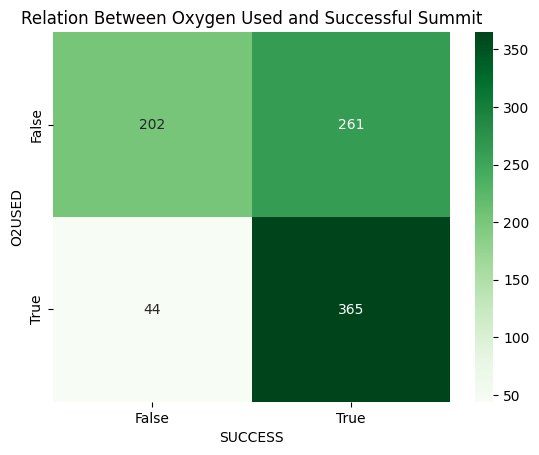

In [ ]:
heatmap_o2 = pd.DataFrame(df_oxygen_success)
sns.heatmap(heatmap_o2, annot=True, fmt="d", cmap="Greens")
plt.title("Relation Between Oxygen Used and Successful Summit")
plt.show()

In [ ]:
import scipy.stats as stats
#How often does bad weather (TERMREASON = 4) play a role in termination compared to technical difficulty (TERMREASON = 10)?

df_term = df_exped["TERMREASON_FACTOR"].value_counts()
print(df_term)

TERMREASON_FACTOR
Success (main peak)                                                             628
Bad weather (storms, high winds)                                                 78
Bad conditions (deep snow, avalanching, falling ice, or rock)                    54
Success (subpeak, foresummit)                                                    26
Illness, AMS, exhaustion, or frostbite                                           25
Unknown                                                                          23
Did not attempt climb                                                            12
Other                                                                            12
Route technically too difficult, lack of experience, strength, or motivation      9
Accident (death or serious injury)                                                5
Lack of time                                                                      4
Lack (or loss) of supplies, support or equipment          

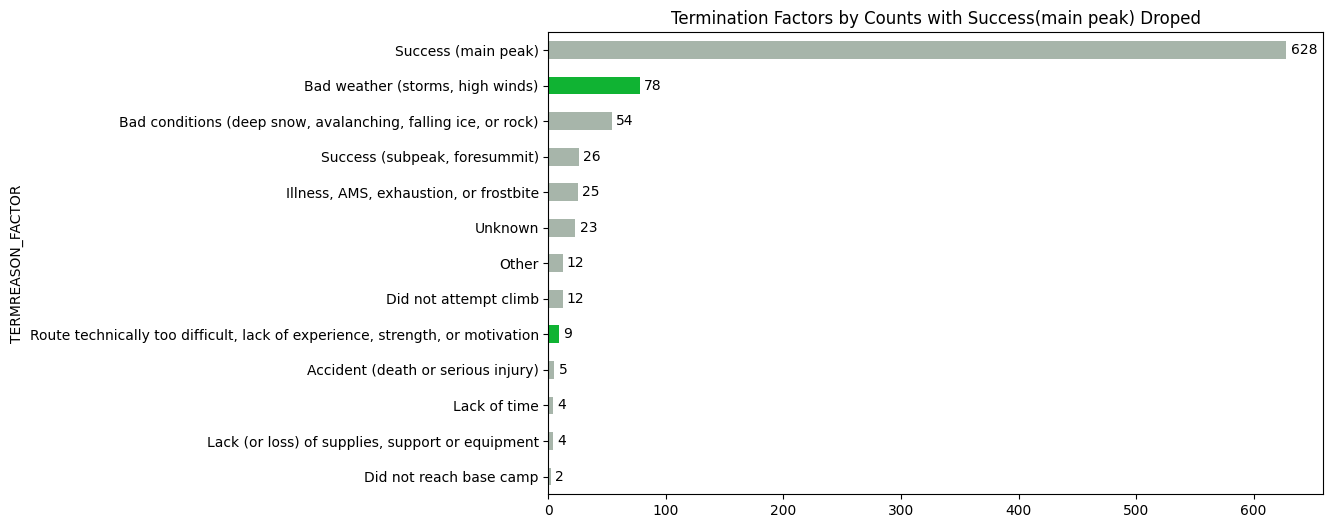

In [ ]:
#df_term = df_term.drop("Success (main peak)")

colors =  ['#a7b5aa','#a7b5aa','#a7b5aa','#a7b5aa','#10b333','#a7b5aa','#a7b5aa','#a7b5aa','#a7b5aa','#a7b5aa','#a7b5aa','#10b333']


df_term = df_term.sort_values(ascending=True)
ax = df_term.plot(kind='barh', stacked=True, color=colors, figsize=(10, 6))
ax.bar_label(ax.containers[0], padding=3)
plt.title("Termination Factors by Counts with Success(main peak) Droped")
plt.show()

<Axes: ylabel='count'>

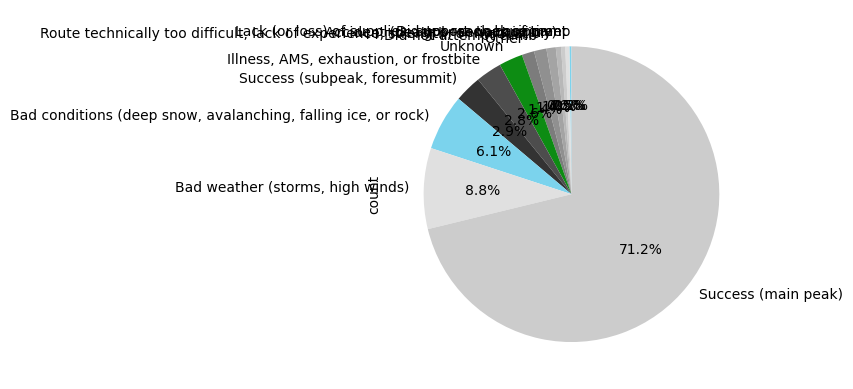

In [ ]:
#NOPE

greyscale_colors = [
    "#7bd3ed",  # Very Light Grey
    '#E0E0E0',
    '#CCCCCC',
    '#B8B8B8',
    '#A4A4A4',  # Mid Grey
    '#909090',
    '#7C7C7C',
    '#0d8c13',
    '#4D4D4D',
    '#333333'   # Dark Charcoal
]

custom_labels = [
    'Bad Weather',
    'Bad Conditions',
    'Subpeak/Foresummit',
    'Illness,AMS,Exaustion, or frosbite',
    'Unknown',
    'Other Routes'
]

df_term.plot.pie(autopct='%1.1f%%', startangle=90,colors=greyscale_colors)

In [ ]:
#Are expeditions with no hired personnel (NOHIRED) associated with higher or lower death rates?

hired_deaths_df = df_exped[["NOHIRED","HDEATHS"]]
correlation, p_value = stats.pointbiserialr(hired_deaths_df['NOHIRED'],hired_deaths_df['HDEATHS'])
print(f"P-value: {p_value:.4f}")
print(f"Point-Biserial Correlation Coefficient: {correlation:.4f}")

P-value: 0.1277
Point-Biserial Correlation Coefficient: -0.0513


In [ ]:
print(hired_deaths_df['HDEATHS'].value_counts())


HDEATHS
0    868
1     12
3      1
2      1
Name: count, dtype: int64


In [ ]:
print(hired_deaths_df['NOHIRED'].value_counts())

NOHIRED
False    736
True     146
Name: count, dtype: int64


In [ ]:
cross = pd.crosstab(hired_deaths_df['NOHIRED'],hired_deaths_df['HDEATHS'])
print(cross)

HDEATHS    0   1  2  3
NOHIRED               
False    722  12  1  1
True     146   0  0  0
